# TP3 – Descente de gradient

# Partie 1 – Descente de gradient en une dimension

1) On développe l'expresssion E(x) : 

$ E(x) = (x−1)(x−2)(x−3)(x−5) $

 $E(x) = (x^2 - 3x + 2)(x^2 - 8x + 15)$

 $E(x) = x^4 -8x^3 +15x^2 -3x^3 + 24x^2 - 45x +2x^2 -16x + 30$

 $E(x) = x^4 -11x^3 +41x^2 -61x + 30 $

 On calcul alors sa dérivée : 

$E'(x) = 4x^3 -33x^2 +82x -61$

Et sa dérivée seconde : 

$E''(x) = 12x^2 -66x +82$




In [547]:
import numpy as np
import matplotlib.pyplot as plt    
import pandas as pd

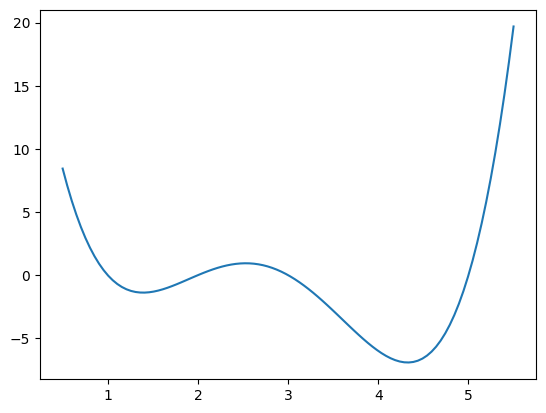

In [548]:
def E(x):
    return (x-1)*(x-2)*(x-3)*(x-5)
x = np.linspace(0.5,5.5,100)
y = E(x)
plt.plot(x, y)
plt.show()

On observe deux minimas locaux, celui aux alentour de x = 4,3 semble être le minimum global.

In [549]:
np.roots([4,-33,82,-61])

array([4.32634546, 2.53090656, 1.39274798])

Le minimum global est donc effectivement atteint en : 4.32634546

On passe à l'implémentation de : def descente_gradient(dE, x0, eta, eps=0.01, nmax=1000):

In [550]:
def dE(x):
    return 4*x**3 - 33* x**2 +82*x -61

def descente_gradient(dE, x0, eta, eps=0.01, nmax=1000):
    i = 0
    x1 = x0 - eta * dE(x0)
    l = [x0,x1]
    while (abs(x1-x0)>=eps) and (i<nmax) :
        x2 = x1 - eta * dE(x1)
        x0 = x1
        x1 = x2
        l.append(x1)
        if abs(x0) > 10**10 :
            print("On a divergé dans notre descente, choisir des valeurs de départ différentes")
            return [0,0,0]
        i = i + 1

    print("le nombre d'itération est :", i)
    print("le minimum est :", x1)
    return  i, x1, l


On teste l'algorithme pour les valeurs suivantes :

(a) x0 = 5 et η= 0.001, l'algorithme devrait s'arrêter tôt avant de tomber sur le vrai minimum

In [551]:
a = descente_gradient(dE, 5, 0.001, eps=0.01, nmax=1000)

le nombre d'itération est : 21
le minimum est : 4.661483315686318


(b) x0 = 5 et η= 0.01 semble être les paramètres les plus raisonnables on devrait s'approcher de notre minimum globale

In [552]:
b = descente_gradient(dE, 5, 0.01, eps=0.01, nmax=1000) 

le nombre d'itération est : 9
le minimum est : 4.361008294913719


(c) x0 = 5 et η= 0.1 un pas un peu grand, on risuqe de se tromper de minimum en tout cas il prendra plus de temps a être trouvé.

In [553]:
c = descente_gradient(dE, 5, 0.1, eps=0.01, nmax=1000)

le nombre d'itération est : 1000
le minimum est : 4.483002473055202


(d) x0 = 5 et η= 0.17 avec une valeur si spécifique on se doute que c'est pour trouver l'autre minimum local

In [554]:
d = descente_gradient(dE, 5, 0.17, eps=0.01, nmax=1000)

le nombre d'itération est : 1000
le minimum est : 1.2378980211216366


(e) x0 = 5 et η= 1 un pas beaucoup trop grand probablement diverge

In [555]:
e = descente_gradient(dE, 5, 1, eps=0.01, nmax=1000)

On a divergé dans notre descente, choisir des valeurs de départ différentes


(f) x0 = 0 et η= 0.001 en partant de 0 avec ce pas on devrait s'arréter avant de tomber sur notre premier minimuum on se rapprochera donc du minimum local le plus proche de 0

In [556]:
f = descente_gradient(dE, 0, 0.001, eps=0.01, nmax=1000)

le nombre d'itération est : 38
le minimum est : 0.9494071180705481


on présente dans un tableau : 

In [557]:
print(d)

(1000, 1.2378980211216366, [5, 0.9199999999999999, 2.6839961599999995, 2.9047609794051503, 3.4511973978532033, 4.578539559686771, 3.459840406221879, 4.5912626140847355, 3.4041016464588525, 4.505525281594883, 3.7566158389109, 4.879121101582515, 1.8018238715742099, 1.2898253932314991, 1.5535775077179976, 1.257211063519484, 1.6174976022473109, 1.2393531272439735, 1.6552327397043327, 1.2377412921289834, 1.6587350302981723, 1.2379176047585754, 1.658351147286891, 1.2378956111529198, 1.658399023185632, 1.2378983182617354, 1.6583931301632824, 1.2378979844940048, 1.6583938567296002, 1.2378980256367562, 1.6583937671674698, 1.2378980205650587, 1.6583937782078562, 1.2378980211902455, 1.6583937768469101, 1.2378980211131787, 1.6583937770146748, 1.2378980211226813, 1.6583937769939903, 1.237898021121505, 1.65839377699655, 1.2378980211216535, 1.6583937769962263, 1.2378980211216342, 1.6583937769962673, 1.237898021121639, 1.658393776996259, 1.2378980211216377, 1.65839377699626, 1.2378980211216366, 1.6583

In [558]:
xmin = [a[1],b[1],c[1],d[1],e[1],f[1]]
Exmin = [dE(a[1]),dE(b[1]),dE(c[1]),dE(d[1]),dE(e[1]),dE(f[1])]
iter = [a[0],b[0],c[0],d[0],e[0],f[0]]
statut = []
i=0
for i in range(5):
    if xmin[i] == 0 :
        statut.append('divergé')
    if iter[i] < 1000:
        statut.append('arrêt par nombre max')
    else :
        statut.append('convergé')  

titre = ['xmin', 'Exmin', 'iter','statut']
t = [xmin, Exmin, iter, statut]

dt = pd.DataFrame(t,index = titre)

print(dt)


                           0                     1         2         3  \
xmin                4.661483              4.361008  4.483002  1.237898   
Exmin               9.335991              0.753184  3.780117 -2.473504   
iter                      21                     9      1000      1000   
statut  arrêt par nombre max  arrêt par nombre max  convergé  convergé   

              4                     5  
xmin          0              0.949407  
Exmin       -61             -9.470871  
iter          0                    38  
statut  divergé  arrêt par nombre max  


Dans le cas f on ne trouve pas le minimum global on tombe sur l'autre minimum local

In [559]:
print(a[2])

[5, 4.976, 4.953232503296, 4.931605767917654, 4.911037247899635, 4.891452439321794, 4.872783898886173, 4.854970405290911, 4.837956239433833, 4.821690564011287, 4.8061268866613895, 4.7912225936523525, 4.776938543399458, 4.763238710932537, 4.750089875924174, 4.7374613481002825, 4.725324724845548, 4.713653676630526, 4.70242375655944, 4.69161223089503, 4.681197927880805, 4.671161102568805, 4.661483315686318]


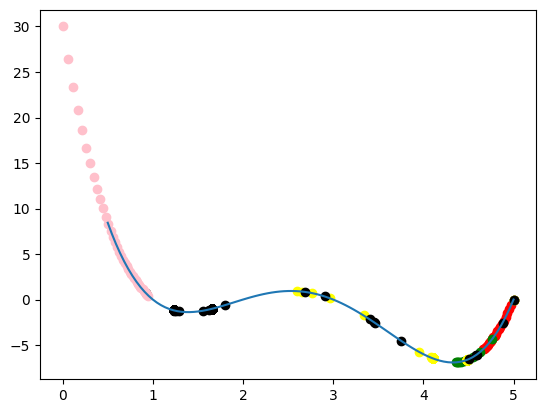

In [560]:
def E(x):
    return (x-1)*(x-2)*(x-3)*(x-5)
x = np.linspace(0.5,5,100)
y = E(x)
plt.plot(x, y)

y1 = [E(x) for x in a[2]]
y2 = [E(x) for x in b[2]]
y3 = [E(x) for x in c[2]]
y4 = [E(x) for x in d[2]]
y6 = [E(x) for x in f[2]]

plt.scatter(a[2],y1,c="red")
plt.scatter(b[2],y2,c="green")
plt.scatter(c[2],y3,c="yellow")
plt.scatter(d[2],y4,c="black")

plt.scatter(f[2],y6,c="pink")

plt.show()

Les cas a,b,f ont une connvergence monotone, le pas est petit, on visualise les xi en fonction de i car on arrive pas a bien voir ce qui se passe :

Text(0, 0.5, 'x_i')

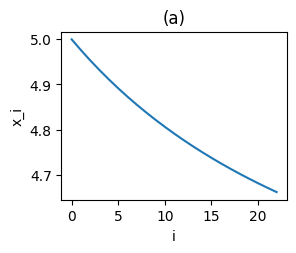

In [561]:
xa = a[2][:41]  
plt.subplot(2, 2, 1)
plt.plot(xa)
plt.title("(a)")
plt.xlabel("i")
plt.ylabel("x_i")

Text(0, 0.5, 'x_i')

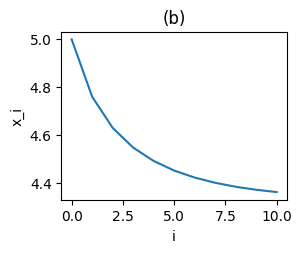

In [562]:
xb = b[2][:41]  
plt.subplot(2, 2, 1)
plt.plot(xb)
plt.title("(b)")
plt.xlabel("i")
plt.ylabel("x_i")

Text(0, 0.5, 'x_i')

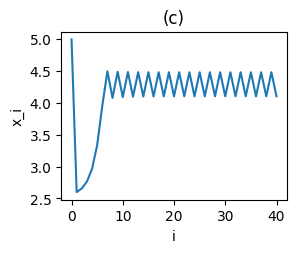

In [563]:
xc = c[2][:41]  
plt.subplot(2, 2, 1)
plt.plot(xc)
plt.title("(c)")
plt.xlabel("i")
plt.ylabel("x_i")

Text(0, 0.5, 'x_i')

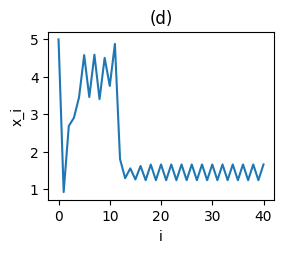

In [564]:
xd = d[2][:41]
plt.subplot(2, 2, 3)
plt.plot(xd)
plt.title("(d)")
plt.xlabel("i")
plt.ylabel("x_i")

Text(0, 0.5, 'x_i')

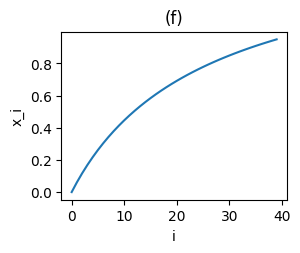

In [565]:
xf = f[2][:41]  
plt.subplot(2, 2, 1)
plt.plot(xf)
plt.title("(f)")
plt.xlabel("i")
plt.ylabel("x_i")

## Question 6

**Démonstration.** Soit $x_1$ un minimum local ($E'(x_1) = 0$, $E''(x_1) > 0$) et $e_i = x_i - x_1$. Le développement de Taylor de $E'$ en $x_1$ donne

$$E'(x_i) = E'(x_1) + E''(x_1)\,(x_i - x_1) + O\big((x_i-x_1)^2\big) = E''(x_1)\,e_i + O(e_i^2)$$

On injecte alors :

$$e_{i+1} = x_{i+1} - x_1 = (x_i - x_1) - \eta\,E'(x_i) = e_i - \eta\,E''(x_1)\,e_i + O(e_i^2) environ = \big(1 - \eta\,E''(x_1)\big)\,e_i$$

Près de $x_1$, on a que l'erreur est multipliée à chaque fois par $q = 1 - \eta\,E''(x_1)$ : $e_i  environ = q^{\,i}\,e_0$.

(a) Conditions sur $\eta$ (avec $E''(x_1) > 0$).
- Convergence locale alors : $ |q| < 1 alors : -1 < 1 - \eta E'' < 1 et donc 0 < \eta < \dfrac{2}{E''(x_1)}$.
- Sans oscillation : l'erreur garde son signe $alors : q \ge 0 alors : \eta \le \dfrac{1}{E''(x_1)}$.


# Question 7

In [566]:
def d2E(x):
    return 12*x**2 - 66*x + 82
 
def E(x):
    return x**4 - 11*x**3 + 41*x**2 - 61*x

In [567]:
eta = 0.01
eps = 1e-6
nmax = 1000
liste_x0 = np.linspace(-1, 6, 200)
 
 

In [568]:
liste_xmin = []
liste_i = [] 
for x0 in liste_x0:
    i, xmin, l = descente_gradient(dE, x0, eta, eps, nmax)
    liste_xmin.append(xmin)
    liste_i.append(i)

le nombre d'itération est : 76
le minimum est : 1.3927423114059296
le nombre d'itération est : 76
le minimum est : 1.3927422219108432
le nombre d'itération est : 76
le minimum est : 1.3927421407750487
le nombre d'itération est : 76
le minimum est : 1.3927420672306607
le nombre d'itération est : 76
le minimum est : 1.3927420006024314
le nombre d'itération est : 76
le minimum est : 1.3927419402955263
le nombre d'itération est : 76
le minimum est : 1.3927418857852123
le nombre d'itération est : 76
le minimum est : 1.3927418366081248
le nombre d'itération est : 76
le minimum est : 1.3927417923548526
le nombre d'itération est : 76
le minimum est : 1.3927417526636217
le nombre d'itération est : 76
le minimum est : 1.392741717214904
le nombre d'itération est : 76
le minimum est : 1.3927416857268016
le nombre d'itération est : 76
le minimum est : 1.3927416579510932
le nombre d'itération est : 76
le minimum est : 1.3927416336698395
le nombre d'itération est : 76
le minimum est : 1.3927416126924

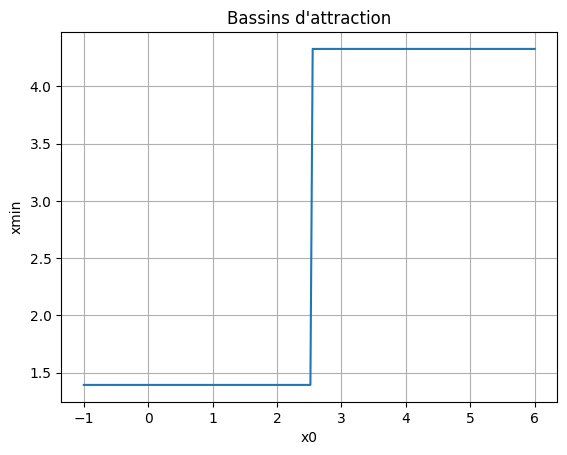

In [569]:
plt.figure()
plt.plot(liste_x0, liste_xmin)
plt.xlabel("x0")
plt.ylabel("xmin")
plt.title("Bassins d'attraction")
plt.grid()
plt.show()

x0 sépare les deux bassin d'attracion vers 2,5 ce qui correspond au maximum locale de notre fonction (le sommet de la bosse). Cela sggère qu'on pourrait différencier les cas et faire différentes descente de gradient en fonction de la convexité de parties de nos fonctions (enfin ça donctionne dans le cas simple). On pourrait trouver les deux minimums de part et d'autres de nos maximums locaux pour établir et trouver les mimums locaux et les trouver tous et en déduire le minimum global.

# Question 8

In [570]:
x0_f = 0.0
eta_f = 0.001
for eps in [1e-2, 1e-4, 1e-6]:
    for nmax in [10, 100, 1000]:
        print("eps =", eps, "nmax =", nmax)
        descente_gradient(dE, x0_f, eta_f, eps, nmax)

eps = 0.01 nmax = 10
le nombre d'itération est : 10
le minimum est : 0.4766605556293884
eps = 0.01 nmax = 100
le nombre d'itération est : 38
le minimum est : 0.9494071180705481
eps = 0.01 nmax = 1000
le nombre d'itération est : 38
le minimum est : 0.9494071180705481
eps = 0.0001 nmax = 10
le nombre d'itération est : 10
le minimum est : 0.4766605556293884
eps = 0.0001 nmax = 100
le nombre d'itération est : 100
le minimum est : 1.2482496139055197
eps = 0.0001 nmax = 1000
le nombre d'itération est : 311
le minimum est : 1.385519036687697
eps = 1e-06 nmax = 10
le nombre d'itération est : 10
le minimum est : 0.4766605556293884
eps = 1e-06 nmax = 100
le nombre d'itération est : 100
le minimum est : 1.2482496139055197
eps = 1e-06 nmax = 1000
le nombre d'itération est : 652
le minimum est : 1.3926748619537044


In [571]:
i, xmin, l = descente_gradient(dE, x0_f, eta_f, 0.01, 1000)
d = abs(xmin -1.39274798)
d


le nombre d'itération est : 38
le minimum est : 0.9494071180705481


0.4433408619294519

Un petit pas ne garantit pas qu'on soit proche du minimum pour deux raison, d'abord c'est un minimum local pas global, le pas n'st pas assez important pour qu'on "dépasse" une bosse et vérifie d'autres minimums, deuxième raison avec un petit pas on risque de ne pas s'approcher suffisamment du minimum local. le fait que eta soit vraiment petit "trompe" notre pas en lui faisant croire qu'on se rapproche du minimum et qu'il peut donc s'arréter alors qu'en réalité la dérivé est encore loin de 0

b) On s'interresse à un autre critère d'arrêt, j'ai trouvé que considérer une pente de dérivé proche de 0 semble être un bon critère d'arrêt (en tout cas en sachant différencier les max des min), on implémente.

In [572]:
def descente_gradient_2(dE, x0, eta, eps=0.01, nmax=1000):
    i = 0
    x = x0
    l = [x]
    while (abs(dE(x)) >= eps) and (i < nmax):
        x = x - eta * dE(x)
        l.append(x)
        i = i + 1
 
    print("le nombre d'itération est :", i)
    print("le minimum est :", x)
    return i, x, l

On compare avec avant :

In [573]:
x0_f = 0.0
eta_f = 0.001
for eps in [1e-2, 1e-4, 1e-6]:
    for nmax in [10, 100, 1000]:
        print("eps =", eps, "nmax =", nmax)
        descente_gradient_2(dE, x0_f, eta_f, eps, nmax)

eps = 0.01 nmax = 10
le nombre d'itération est : 10
le minimum est : 0.44602454238514505
eps = 0.01 nmax = 100
le nombre d'itération est : 100
le minimum est : 1.2459249449712393
eps = 0.01 nmax = 1000
le nombre d'itération est : 481
le minimum est : 1.392008791777926
eps = 0.0001 nmax = 10
le nombre d'itération est : 10
le minimum est : 0.44602454238514505
eps = 0.0001 nmax = 100
le nombre d'itération est : 100
le minimum est : 1.2459249449712393
eps = 0.0001 nmax = 1000
le nombre d'itération est : 823
le minimum est : 1.3927405456698816
eps = 1e-06 nmax = 10
le nombre d'itération est : 10
le minimum est : 0.44602454238514505
eps = 1e-06 nmax = 100
le nombre d'itération est : 100
le minimum est : 1.2459249449712393
eps = 1e-06 nmax = 1000
le nombre d'itération est : 1000
le minimum est : 1.3927472928863285


On observe qu'il a l'air plus efficace que l'autre si on a plus d'itération.

c) Le problème c'est que si on prend pas la valeur absolu on va valider la condition immédiatment dès qu'on se déplace vers la gauche, on s'arrète immédiatement. ça passera inaperçut en se déplaçant de l'autre coté vers le droite.

# Partie 2 – Descente de gradient pour la régression linéaire

# Q1) On calcul les dérivées partielles et on les écris sous forme vectorielle :

$$\frac{\partial E}{\partial a} = \sum_{i=1}^n 2\,r_i\,x_i \qquad\qquad \frac{\partial E}{\partial b} = \sum_{i=1}^n 2\,r_i$$

Forme vectorielle : 

$$\frac{\partial E}{\partial a} = 2\,\mathbf{x}^\top \mathbf{r} \qquad\qquad \frac{\partial E}{\partial b} = 2\,\mathbf{1}^\top \mathbf{r} = 2\sum_i r_i$$

avec : $\mathbf{r} = \hat{\mathbf{y}} - \mathbf{y} = a\,\mathbf{x} + b\,\mathbf{1} - \mathbf{y}$ (et 1 le vecteur avec que des 1)


# Q2) On fait l'algo :


In [574]:
def E_reg(a, b, x, y):
    r = a*x + b - y
    return np.sum(r**2)

def descente_gradient_3(x, y, a0, b0, eta, nmax):
    a = a0
    b = b0
    l_a = [a]
    l_b = [b]
    liste_E = []
    for i in range(nmax):
        r = a*x + b - y
        grad_a = 2*np.sum(r*x)
        grad_b = 2*np.sum(r)
        a = a - eta*grad_a
        b = b - eta*grad_b
        l_a.append(a)
        l_b.append(b)
        liste_E.append(E_reg(a, b, x, y))
        if abs(a) > 1e10 or abs(b) > 1e10:
            print("diverge", i + 1)
            break
    return a, b, liste_E, l_a, l_b,i

Si on fait l'un après l'autre on calcul pas la même chose, on aura pas pris les dérivées partielles au même point. Je suis pas sûr si c'est grave ou non mais ça reste une erreur de compréhension de ce qu'on essaye de faire, on descend pas une variable après l'autre, on suit le gradient donc à partir d'un même point on décide de la direction dans laquelle on continue.

3) on génère un problème aléatoire de régression et on applique. Avant d'appliquer prédiction : un pas dix fois plus grand devrait accélérer notre descente de gradient surtout qu'on part avec des valeurs petites.

In [575]:
from sklearn import datasets
X ,y= datasets.make_regression(n_samples=100, n_features=1, noise=10, random_state=0)
x  = X.ravel()      

4) on fait les régressions : 

In [576]:
res_a = descente_gradient_3(x, y, 0, 0, 0.001, 100)
res_b = descente_gradient_3(x, y, 0, 0, 0.001, 500)
res_c = descente_gradient_3(x, y, 0, 0, 0.001, 1000)
res_d = descente_gradient_3(x, y, 0, 0, 0.01, 1000)
res_e = descente_gradient_3(x, y, 0, 0, 1, 1000)
for nom, res in [("(a)", res_a), ("(b)", res_b), ("(c)", res_c), ("(d)", res_d), ("(e)", res_e)]:
    print(nom, "a =", res[0], " b =", res[1], " E =", res[2][-1], " i =", len(res[2]))

diverge 151
diverge 4
(a) a = 42.61943027732904  b = -0.8141818122369194  E = 11417.148616819482  i = 100
(b) a = 42.61943029136693  b = -0.8141818270307261  E = 11417.148616819482  i = 500
(c) a = 42.61943029136693  b = -0.8141818270307261  E = 11417.148616819482  i = 1000
(d) a = 10283429172.642084  b = 8749714245.333975  E = 1.9512102516400817e+22  i = 151
(e) a = -73376111833.1099  b = -15299967997.650518  E = 5.856900133535949e+23  i = 4


(ce sont d et e qui diverge), on obtient environ les mêmes résultats pour a,b,c

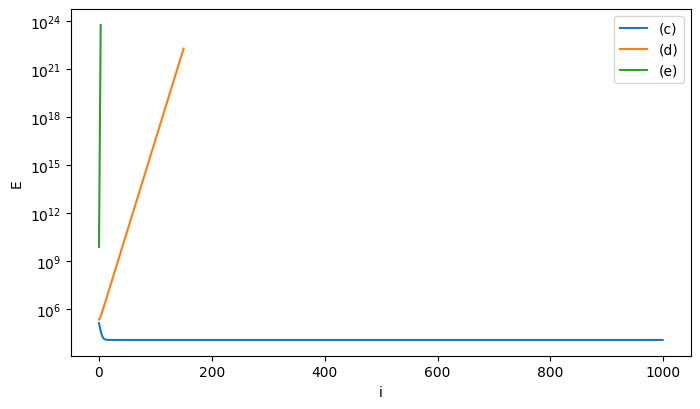

In [577]:
plt.figure(figsize=(8, 4.5))
plt.semilogy(res_c[2], label="(c)")
plt.semilogy(res_d[2], label="(d)")
plt.semilogy(res_e[2], label="(e)")
plt.xlabel("i")
plt.ylabel("E")
plt.legend()
plt.show()

Il n'était clairment pas utile d'aller jusqu'à 100 dans le cas de (c), une cinquantaine ont l'air d'être suffisant.

# Q5) On veut expliquer le cas d)

a) Après calculs on obtient : 
$$H = 2\begin{pmatrix} \sum x_i^2 & \sum x_i \\ \sum x_i & n \end{pmatrix}$$

Ne dépend effectivement pas de a et b, polynome en (a,b) donc dérivée deux fois donne des constantes dans la hessienne.

b) On veut calculer le pas critique $2 / \lambda_{max} $ :


In [578]:
S1 = np.sum(x)
S2 = np.sum(x**2)
H = 2*np.array([[S2, S1],
                [S1, n]])
valeurs_propres = np.linalg.eig(H)[0]
print(valeurs_propres)


[214.05832172 189.82240187]


In [579]:
2/valeurs_propres[0]

0.009343248064026394

Ce qui valide bien nos résultat de divergence juste avant. en faisant les valeurs $ \eta * \lambda_{max} $ pour chacun on obtient l'explication vérifiée que ça converge ou diverge au vu de nos seuils.

c) La hessienne devient $H/n$, donc $\lambda_{\max}$ est divisée par $n$ et le pas critique est **multiplié par $n$**

In [580]:
def descente_gradient_4(x, y, a0, b0, eta, nmax):
    n = len(x)
    a = a0
    b = b0
    l_a = [a]
    l_b = [b]
    liste_E = []
    for i in range(nmax):
        r = a*x + b - y
        grad_a = 2*np.sum(r*x)/n
        grad_b = 2*np.sum(r)/n
        a = a - eta*grad_a
        b = b - eta*grad_b
        l_a.append(a)
        l_b.append(b)
        liste_E.append(E_reg(a, b, x, y))
        if abs(a) > 1e10 or abs(b) > 1e10:
            print("diverge", i + 1)
            break
    return a, b, liste_E, l_a, l_b,i

In [581]:
a = descente_gradient_4(x, y, 0, 0, 0.1, 1000)
b = descente_gradient_4(x, y, 0, 0, 1, 1000)
print("a =", a[0], " b =", a[1], " E/n =", a[2][-1])
print("a =", b[0], " b =", b[1], " E/n =", b[2][-1])

diverge 151
a = 42.61943029136693  b = -0.8141818270307261  E/n = 11417.148616819482
a = 10283429172.642052  b = 8749714245.33396  E/n = 1.9512102516400717e+22


Je suppose que les bibliothèques utilise la moyenne plutot que la somme pour ce n, ça ne change pas avec la taille des données.

# 6) On compare avec la fonction de stats.linregress de scipy

In [582]:
from scipy import stats
resultat = stats.linregress(x, y)
a_s = resultat.slope
b_s = resultat.intercept

print(" a =", a_s, " b =", b_s, " E =", E_reg(a_s, b_s, x, y))

 a = 42.619430291366946  b = -0.8141818270307257  E = 11417.148616819482


On a l'air d'obtenir les mêmes résultats, l'écart doit être minime.

Je suppose qu'il existe pleins de cas pratiques qui nous permettent pas d'utiliser et trouver les solutions exactes, que ce soit des problèmes de dérivations ou des soucis de complexité de calculs ou autres.

# 7) On visualise

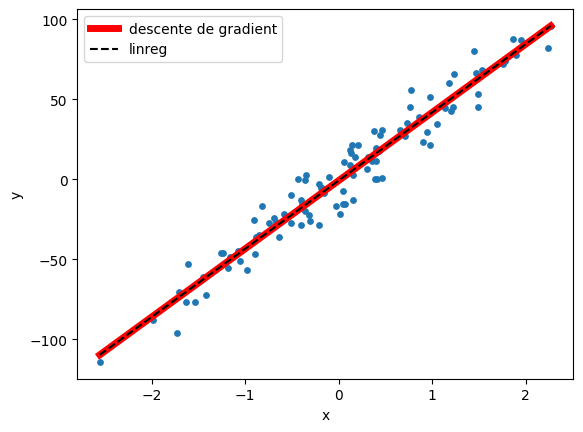

In [583]:
xs = np.linspace(x.min(), x.max(), 100)

plt.scatter(x, y, s=15)
plt.plot(xs, res_c[0]*xs + res_c[1],'r', linewidth=5, label="descente de gradient")
plt.plot(xs, a_s*xs + b_s, "k--", label="linreg")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()